In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import Dataset, DataLoader

import random
import torchvision
from torch import nn
from torchvision.models import resnet18, ResNet18_Weights

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

In [2]:
MANIFEST_PATH = Path(
    "/kaggle/input/notebooks/zidanefatuna/"
    "07-batch-dicom-to-volume-preprocessing/"
    "preprocessed/processed_manifest.csv"
)

DATA_ROOT = MANIFEST_PATH.parent

manifest = pd.read_csv(
    MANIFEST_PATH,
    dtype={
        "StudyInstanceUID": str,
        "SeriesInstanceUID": str,
    },
)

assert len(manifest) == 174
assert manifest["status"].eq("ok").all()
assert manifest["StudyInstanceUID"].nunique() == 58

missing_files = [
    relative_path
    for relative_path in manifest["processed_relative_path"]
    if not (DATA_ROOT / relative_path).is_file()
]

print("Series:", len(manifest))
print("Studies:", manifest["StudyInstanceUID"].nunique())
print("Missing processed files:", len(missing_files))

assert not missing_files, "Check DATA_ROOT and the attached output files."

print("\nStudies per split:")
print(
    manifest[["StudyInstanceUID", "split"]]
    .drop_duplicates()["split"]
    .value_counts()
)

Series: 174
Studies: 58
Missing processed files: 0

Studies per split:
split
train         46
validation    12
Name: count, dtype: int64


In [3]:
TARGET_COLUMNS = [
    "ACL", "MCL",
    "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA",
    "Effusion", "Synovitis", "Baker's",
    "Contusion", "Fracture",
]

PLANES = ("Sagittal", "Coronal", "Axial")


class KneeStudyDataset(Dataset):
    def __init__(self, manifest, data_root, split):
        self.data_root = Path(data_root)
        rows = manifest.loc[manifest["split"].eq(split)].copy()

        if rows.empty:
            raise ValueError(f"No studies found for split: {split}")

        self.studies = []

        for study_id, group in rows.groupby("StudyInstanceUID", sort=True):
            if (
                len(group) != len(PLANES)
                or set(group["Anatomical_Plane"]) != set(PLANES)
            ):
                raise ValueError(f"Expected one series per plane: {study_id}")

            labels = group[TARGET_COLUMNS].to_numpy(dtype=np.float32)

            if not np.isin(labels, [0, 1]).all():
                raise ValueError(f"Invalid labels: {study_id}")

            if not np.all(labels == labels[0]):
                raise ValueError(f"Inconsistent study labels: {study_id}")

            by_plane = group.set_index("Anatomical_Plane")

            self.studies.append({
                "study_id": study_id,
                "paths": {
                    plane: by_plane.loc[plane, "processed_relative_path"]
                    for plane in PLANES
                },
                "labels": labels[0].copy(),
            })

    def __len__(self):
        return len(self.studies)

    def __getitem__(self, index):
        study = self.studies[index]
        images = {}

        for plane in PLANES:
            volume = np.load(
                self.data_root / study["paths"][plane],
                allow_pickle=False,
            )

            if volume.ndim != 3 or volume.shape[1:] != (224, 224):
                raise ValueError(f"Unexpected volume shape: {volume.shape}")

            # (slices, height, width) → (channel, slices, height, width)
            images[plane] = torch.from_numpy(
                np.ascontiguousarray(volume, dtype=np.float32)
            ).unsqueeze(0)

        return {
            "study_id": study["study_id"],
            "images": images,
            "labels": torch.from_numpy(study["labels"].copy()),
        }

In [4]:
train_dataset = KneeStudyDataset(manifest, DATA_ROOT, split="train")
validation_dataset = KneeStudyDataset(
    manifest, DATA_ROOT, split="validation"
)

sample = train_dataset[0]

print("Training studies:", len(train_dataset))
print("Validation studies:", len(validation_dataset))

for plane, image in sample["images"].items():
    print(plane, tuple(image.shape), image.dtype)

print("Labels:", sample["labels"])
print("Label shape:", tuple(sample["labels"].shape))

Training studies: 46
Validation studies: 12
Sagittal (1, 36, 224, 224) torch.float32
Coronal (1, 30, 224, 224) torch.float32
Axial (1, 32, 224, 224) torch.float32
Labels: tensor([0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 0.])
Label shape: (12,)


In [5]:
train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42),
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

batch = next(iter(train_loader))

for plane, images in batch["images"].items():
    print(plane, tuple(images.shape))

print("Labels:", tuple(batch["labels"].shape))
print("Study IDs:", batch["study_id"])

Sagittal (1, 1, 36, 224, 224)
Coronal (1, 1, 30, 224, 224)
Axial (1, 1, 32, 224, 224)
Labels: (1, 12)
Study IDs: ['1.2.826.0.1.3680043.8.498.10095687747295410396510538520594649149']


In [6]:
train_dataset = KneeStudyDataset(
    manifest, DATA_ROOT, split="train"
)

validation_dataset = KneeStudyDataset(
    manifest, DATA_ROOT, split="validation"
)

print(len(train_dataset), len(validation_dataset))

46 12


In [7]:
# ImageNet normalization expected by the pretrained ResNet-18.
imagenet_mean = torch.tensor(
    [0.485, 0.456, 0.406], device=device
).view(1, 3, 1, 1)

imagenet_std = torch.tensor(
    [0.229, 0.224, 0.225], device=device
).view(1, 3, 1, 1)


@torch.inference_mode()
def extract_study_features(sample, chunk_size=16):
    plane_features = []

    for plane in PLANES:
        # Dataset sample: (1, D, H, W) → (D, 1, H, W).
        slices = sample["images"][plane].permute(1, 0, 2, 3)
        feature_sum = torch.zeros(512, device=device)

        for chunk in slices.split(chunk_size):
            chunk = chunk.to(device)

            # Grayscale → three identical channels.
            chunk = chunk.repeat(1, 3, 1, 1)
            chunk = (chunk - imagenet_mean) / imagenet_std

            features = encoder(chunk)
            feature_sum += features.sum(dim=0)

        plane_features.append(
            (feature_sum / len(slices)).cpu()
        )

    return torch.cat(plane_features)

In [8]:
import torch
from torch import nn
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

encoder = resnet18(weights=ResNet18_Weights.DEFAULT)
encoder.fc = nn.Identity()

encoder = encoder.to(device)
encoder.requires_grad_(False)
encoder.eval()

print("Device:", device)
print(
    "Trainable encoder parameters:",
    sum(p.numel() for p in encoder.parameters() if p.requires_grad),
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 160MB/s]


Device: cpu
Trainable encoder parameters: 0


In [9]:
weights = ResNet18_Weights.DEFAULT

encoder = resnet18(weights=weights)
encoder.fc = nn.Identity()

encoder = encoder.to(device)
encoder.requires_grad_(False)
encoder.eval()

print(
    "Trainable encoder parameters:",
    sum(p.numel() for p in encoder.parameters() if p.requires_grad),
)

Trainable encoder parameters: 0


In [10]:
sample = train_dataset[0]
study_features = extract_study_features(sample)

print("Feature shape:", tuple(study_features.shape))
print("All finite:", torch.isfinite(study_features).all().item())
print("Labels shape:", tuple(sample["labels"].shape))

Feature shape: (1536,)
All finite: True
Labels shape: (12,)


In [11]:
from tqdm.auto import tqdm

FEATURE_DIR = Path("/kaggle/working/baseline_features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)


def extract_dataset_features(dataset, split):
    features = []
    labels = []
    study_ids = []

    encoder.eval()

    for index in tqdm(
        range(len(dataset)),
        desc=f"Extracting {split}",
    ):
        sample = dataset[index]

        features.append(
            extract_study_features(sample).numpy()
        )
        labels.append(sample["labels"].numpy())
        study_ids.append(sample["study_id"])

    features = np.stack(features).astype(np.float32)
    labels = np.stack(labels).astype(np.float32)
    study_ids = np.asarray(study_ids, dtype=str)

    assert features.shape == (len(dataset), 1536)
    assert labels.shape == (len(dataset), 12)
    assert np.isfinite(features).all()

    np.savez_compressed(
        FEATURE_DIR / f"{split}_features.npz",
        features=features,
        labels=labels,
        study_ids=study_ids,
        target_columns=np.asarray(TARGET_COLUMNS, dtype=str),
        planes=np.asarray(PLANES, dtype=str),
    )

    return features, labels, study_ids

In [12]:
X_train, y_train, train_ids = extract_dataset_features(
    train_dataset, "train"
)

X_val, y_val, val_ids = extract_dataset_features(
    validation_dataset, "validation"
)

assert set(train_ids).isdisjoint(set(val_ids))

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Saved to:", FEATURE_DIR)

Extracting train:   0%|          | 0/46 [00:00<?, ?it/s]

Extracting validation:   0%|          | 0/12 [00:00<?, ?it/s]

Training: (46, 1536) (46, 12)
Validation: (12, 1536) (12, 12)
Saved to: /kaggle/working/baseline_features


In [13]:
from torch import nn

# Estimate probabilities using training labels only.
prevalence = y_train.mean(axis=0)
prevalence = np.clip(prevalence, 1e-6, 1 - 1e-6)

reference_predictions = np.repeat(
    prevalence[None, :],
    repeats=len(y_val),
    axis=0,
)

reference_loss = nn.BCELoss()(
    torch.from_numpy(reference_predictions),
    torch.from_numpy(y_val),
).item()

reference_table = pd.DataFrame({
    "target": TARGET_COLUMNS,
    "training_prevalence": prevalence,
    "validation_prevalence": y_val.mean(axis=0),
})

display(reference_table.round(3))
print("Prevalence baseline validation BCE:", round(reference_loss, 4))

,target,training_prevalence,validation_prevalence
0,ACL,0.391,0.500
1,MCL,0.130,0.250
2,Medial Meniscus,0.391,0.667
3,Lateral Meniscus,0.435,0.250
4,Medial OA,0.283,0.167
5,Lateral OA,0.174,0.250
6,PF OA,0.348,0.417
7,Effusion,0.587,0.667
8,Synovitis,0.413,0.667
9,Baker's,0.196,0.250


Prevalence baseline validation BCE: 0.6685


In [14]:
# Fit scaling on training features only.
feature_mean = X_train.mean(axis=0, keepdims=True)
feature_std = X_train.std(axis=0, keepdims=True)
feature_std = np.where(feature_std < 1e-6, 1.0, feature_std)

X_train_scaled = (X_train - feature_mean) / feature_std
X_val_scaled = (X_val - feature_mean) / feature_std

# These small feature matrices can stay on CPU.
train_features = torch.from_numpy(X_train_scaled).float()
val_features = torch.from_numpy(X_val_scaled).float()
train_targets = torch.from_numpy(y_train).float()
val_targets = torch.from_numpy(y_val).float()

torch.manual_seed(42)

classifier = nn.Linear(1536, 12)

# Start at the training-prevalence prediction.
with torch.no_grad():
    classifier.weight.zero_()
    classifier.bias.copy_(
        torch.from_numpy(np.log(prevalence / (1 - prevalence)))
    )

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    classifier.parameters(),
    lr=1e-3,
    weight_decay=0.1,
)

In [15]:
import copy

history = []

# Epoch 0 is the prevalence prediction, before training.
classifier.eval()
with torch.no_grad():
    initial_val_loss = criterion(
        classifier(val_features), val_targets
    ).item()

best_val_loss = initial_val_loss
best_epoch = 0
best_state = copy.deepcopy(classifier.state_dict())

for epoch in range(1, 101):
    classifier.train()
    optimizer.zero_grad()

    loss = criterion(classifier(train_features), train_targets)
    loss.backward()
    optimizer.step()

    classifier.eval()
    with torch.no_grad():
        train_loss = criterion(
            classifier(train_features), train_targets
        ).item()
        val_loss = criterion(
            classifier(val_features), val_targets
        ).item()

    history.append({
        "epoch": epoch,
        "train_bce": train_loss,
        "validation_bce": val_loss,
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(classifier.state_dict())

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"train BCE: {train_loss:.4f} | "
            f"validation BCE: {val_loss:.4f}"
        )

classifier.load_state_dict(best_state)

history = pd.DataFrame(history)

print("\nBest epoch:", best_epoch)
print("Best validation BCE:", round(best_val_loss, 4))
print("Prevalence reference BCE:", round(reference_loss, 4))

Epoch   1 | train BCE: 0.5111 | validation BCE: 0.6475
Epoch  10 | train BCE: 0.1855 | validation BCE: 0.7402
Epoch  20 | train BCE: 0.0849 | validation BCE: 0.8871
Epoch  30 | train BCE: 0.0503 | validation BCE: 1.0002
Epoch  40 | train BCE: 0.0357 | validation BCE: 1.0847
Epoch  50 | train BCE: 0.0282 | validation BCE: 1.1464
Epoch  60 | train BCE: 0.0237 | validation BCE: 1.1942
Epoch  70 | train BCE: 0.0205 | validation BCE: 1.2335
Epoch  80 | train BCE: 0.0181 | validation BCE: 1.2681
Epoch  90 | train BCE: 0.0162 | validation BCE: 1.3006
Epoch 100 | train BCE: 0.0147 | validation BCE: 1.3321

Best epoch: 2
Best validation BCE: 0.639
Prevalence reference BCE: 0.6685


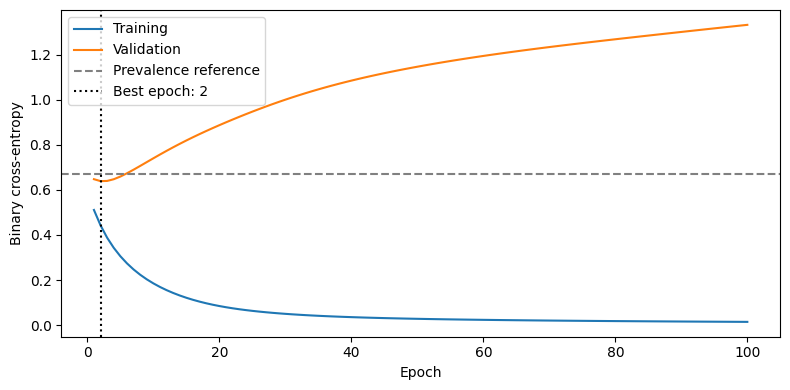

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(history["epoch"], history["train_bce"], label="Training")
ax.plot(
    history["epoch"],
    history["validation_bce"],
    label="Validation",
)

ax.axhline(
    reference_loss,
    color="gray",
    linestyle="--",
    label="Prevalence reference",
)
ax.axvline(
    best_epoch,
    color="black",
    linestyle=":",
    label=f"Best epoch: {best_epoch}",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Binary cross-entropy")
ax.legend()

plt.tight_layout()
plt.show()

In [17]:
classifier.eval()

with torch.no_grad():
    val_logits = classifier(val_features)
    val_probabilities = torch.sigmoid(val_logits).numpy()

    model_bce = nn.functional.binary_cross_entropy_with_logits(
        val_logits,
        val_targets,
        reduction="none",
    ).mean(dim=0).numpy()

reference_bce = -(
    y_val * np.log(reference_predictions)
    + (1 - y_val) * np.log(1 - reference_predictions)
).mean(axis=0)

target_results = pd.DataFrame({
    "target": TARGET_COLUMNS,
    "validation_positive": y_val.sum(axis=0).astype(int),
    "reference_bce": reference_bce,
    "model_bce": model_bce,
})

# Positive means the image classifier has lower loss.
target_results["improvement"] = (
    target_results["reference_bce"] - target_results["model_bce"]
)

display(target_results.round(4))

,target,validation_positive,reference_bce,model_bce,improvement
0,ACL,6,0.7174,0.7775,-0.0601
1,MCL,3,0.6140,0.6636,-0.0496
2,Medial Meniscus,8,0.7910,0.8419,-0.0509
3,Lateral Meniscus,3,0.6361,0.5869,0.0493
4,Medial OA,2,0.4874,0.4094,0.0780
5,Lateral OA,3,0.5806,0.4554,0.1252
6,PF OA,5,0.6894,0.6649,0.0245
7,Effusion,8,0.6499,0.6275,0.0224
8,Synovitis,8,0.7671,0.6392,0.1279
9,Baker's,3,0.5711,0.5782,-0.0071


In [18]:
RESULT_DIR = Path("/kaggle/working/baseline_results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "classifier_state_dict": classifier.state_dict(),
        "feature_mean": torch.from_numpy(feature_mean),
        "feature_std": torch.from_numpy(feature_std),
        "target_columns": TARGET_COLUMNS,
        "planes": list(PLANES),
        "encoder": "resnet18",
        "encoder_weights": str(weights),
        "pooling": "mean",
        "best_epoch": best_epoch,
        "validation_bce": best_val_loss,
        "reference_bce": reference_loss,
    },
    RESULT_DIR / "baseline_checkpoint.pt",
)

history.to_csv(RESULT_DIR / "training_history.csv", index=False)
target_results.to_csv(RESULT_DIR / "target_results.csv", index=False)

predictions = pd.DataFrame(
    val_probabilities,
    columns=TARGET_COLUMNS,
)
predictions.insert(0, "StudyInstanceUID", val_ids)
predictions.to_csv(
    RESULT_DIR / "validation_predictions.csv",
    index=False,
)

print("Saved baseline results to:", RESULT_DIR)

Saved baseline results to: /kaggle/working/baseline_results


In [19]:
regularized_classifier = nn.Linear(1536, 12)

with torch.no_grad():
    regularized_classifier.weight.zero_()
    regularized_classifier.bias.copy_(
        torch.from_numpy(np.log(prevalence / (1 - prevalence)))
    )

regularized_optimizer = torch.optim.Adam(
    regularized_classifier.parameters(),
    lr=1e-3,
)

l2_strength = 0.1
regularized_history = []

regularized_best_loss = initial_val_loss
regularized_best_epoch = 0
regularized_best_state = copy.deepcopy(
    regularized_classifier.state_dict()
)

for epoch in range(1, 101):
    regularized_classifier.train()
    regularized_optimizer.zero_grad()

    logits = regularized_classifier(train_features)
    data_loss = criterion(logits, train_targets)

    # Sum weights within each target, then average over targets.
    # Biases are not penalized.
    penalty = (
        regularized_classifier.weight.square()
        .sum(dim=1)
        .mean()
    )

    objective = data_loss + l2_strength * penalty
    objective.backward()
    regularized_optimizer.step()

    regularized_classifier.eval()
    with torch.no_grad():
        train_bce = criterion(
            regularized_classifier(train_features), train_targets
        ).item()
        val_bce = criterion(
            regularized_classifier(val_features), val_targets
        ).item()

    regularized_history.append({
        "epoch": epoch,
        "train_bce": train_bce,
        "validation_bce": val_bce,
    })

    if val_bce < regularized_best_loss:
        regularized_best_loss = val_bce
        regularized_best_epoch = epoch
        regularized_best_state = copy.deepcopy(
            regularized_classifier.state_dict()
        )

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d} | train BCE: {train_bce:.4f} | "
            f"validation BCE: {val_bce:.4f}"
        )

regularized_classifier.load_state_dict(regularized_best_state)
regularized_history = pd.DataFrame(regularized_history)

print("\nRegularized best epoch:", regularized_best_epoch)
print("Regularized validation BCE:", round(regularized_best_loss, 4))
print("Original baseline BCE:", round(best_val_loss, 4))
print("Prevalence reference BCE:", round(reference_loss, 4))

Epoch   1 | train BCE: 0.5111 | validation BCE: 0.6475
Epoch  10 | train BCE: 0.1854 | validation BCE: 0.7388
Epoch  20 | train BCE: 0.0867 | validation BCE: 0.8763
Epoch  30 | train BCE: 0.0551 | validation BCE: 0.9649
Epoch  40 | train BCE: 0.0440 | validation BCE: 1.0079
Epoch  50 | train BCE: 0.0402 | validation BCE: 1.0193
Epoch  60 | train BCE: 0.0394 | validation BCE: 1.0145
Epoch  70 | train BCE: 0.0396 | validation BCE: 1.0042
Epoch  80 | train BCE: 0.0399 | validation BCE: 0.9955
Epoch  90 | train BCE: 0.0400 | validation BCE: 0.9913
Epoch 100 | train BCE: 0.0399 | validation BCE: 0.9891

Regularized best epoch: 2
Regularized validation BCE: 0.639
Original baseline BCE: 0.639
Prevalence reference BCE: 0.6685


In [20]:
regularized_history.to_csv(
    RESULT_DIR / "l2_training_history.csv",
    index=False,
)

pd.DataFrame([
    {
        "model": "prevalence",
        "best_epoch": 0,
        "validation_bce": reference_loss,
    },
    {
        "model": "original_linear",
        "best_epoch": best_epoch,
        "validation_bce": best_val_loss,
    },
    {
        "model": "explicit_l2_linear",
        "best_epoch": regularized_best_epoch,
        "validation_bce": regularized_best_loss,
    },
]).to_csv(
    RESULT_DIR / "experiment_comparison.csv",
    index=False,
)